<a href="https://colab.research.google.com/github/ChandrimaGhorai/OutbreakTrack/blob/main/Outbreak.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

=== OutbreakTracker: Epidemiological Control Console ===
Select Analysis Mode:
1. Experiment with Live Dataset (Preset Pathogens with Parameter Tweaks)
2. Enter New Custom Dataset (Full Manual Input)

Enter choice (1 or 2): 1

--- Live Dataset Experimentation Mode ---
Select base pathogen profile:
1. COVID-19 Variant Profile (Default beta: 0.45, Recovery: 10d)
2. Seasonal Influenza Profile (Default beta: 0.3, Recovery: 7d)
3. Chronic Carrier Pathogen (e.g., Typhoid) (Default beta: 0.25, Recovery: 21d)
Select option (1, 2, or 3): 1

Loaded baseline: COVID-19 Variant Profile
Tip: Press [Enter] to keep default preset values, or type a new number to experiment/override.
Enter Population Size [100000]: 
Enter Transmission Rate beta [0.45]: 
Enter Shedding Duration in Days [10]: 
Enter Simulation Days [90]: 

OUTBREAK SIMULATION REPORT (COVID-19 Variant Profile (Experimental))
Population Size         : 100000
Transmission Rate (beta): 0.45
Estimated R0            : 4.5
Peak Asymptomatic Load

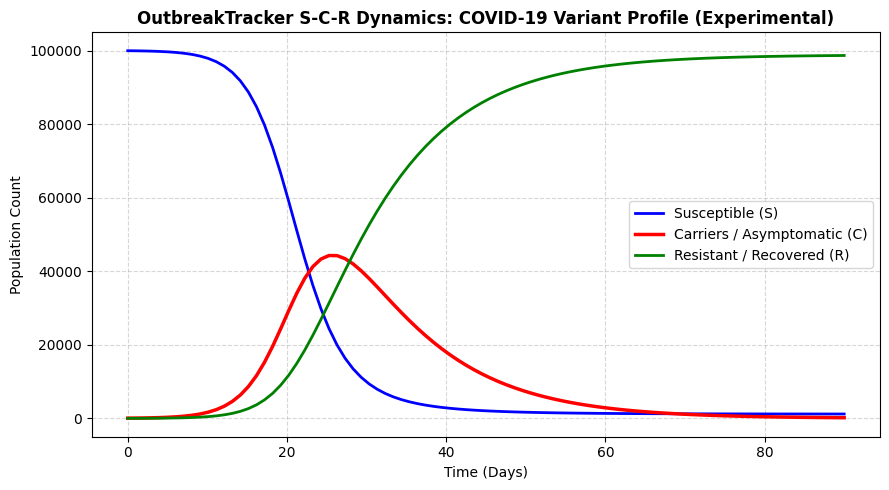

In [ ]:
# ==========================================
# OutbreakTracker Dual-Mode Engine
# ==========================================

import numpy as np
from scipy.integrate import odeint
import matplotlib.pyplot as plt

def scr_model(y, t, beta, gamma, N):
    S, C, R = y
    dS_dt = -beta * (S * C) / N
    dC_dt = (beta * (S * C) / N) - (gamma * C)
    dR_dt = gamma * C
    return [dS_dt, dC_dt, dR_dt]

def run_simulation_and_plot(N, C0, beta, recovery_days, days, title_prefix):
    gamma = 1.0 / recovery_days
    S0 = max(0.0, N - C0)
    R0 = 0.0
    y0 = [S0, C0, R0]

    t = np.linspace(0, days, days)
    results = odeint(scr_model, y0, t, args=(beta, gamma, N))
    S, C, R = results.T

    # Analytical Metrics
    peak_day = int(np.argmax(C))
    peak_carriers = int(C[peak_day])
    total_infected = int(N - S[-1])

    print("\n" + "="*50)
    print(f"OUTBREAK SIMULATION REPORT ({title_prefix})")
    print("="*50)
    print(f"Population Size         : {int(N)}")
    print(f"Transmission Rate (beta): {beta}")
    print(f"Estimated R0            : {round(beta / gamma, 2)}")
    print(f"Peak Asymptomatic Load  : {peak_carriers} carriers on Day {peak_day}")
    print(f"Total Cumulative Cases  : {total_infected} individuals")

    # Plotting Curve
    plt.figure(figsize=(9, 5))
    plt.plot(t, S, label="Susceptible (S)", color="blue", linewidth=2)
    plt.plot(t, C, label="Carriers / Asymptomatic (C)", color="red", linewidth=2.5)
    plt.plot(t, R, label="Resistant / Recovered (R)", color="green", linewidth=2)

    plt.title(f"OutbreakTracker S-C-R Dynamics: {title_prefix}", fontsize=12, fontweight='bold')
    plt.xlabel("Time (Days)", fontsize=10)
    plt.ylabel("Population Count", fontsize=10)
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.legend(fontsize=10)
    plt.tight_layout()

    filename = "outbreak_simulation_curve.png"
    plt.savefig(filename, dpi=300)
    print(f"\n[Success] Outbreak curve plot saved as '{filename}'.")
    plt.show()

def main():
    print("=== OutbreakTracker: Epidemiological Control Console ===")
    print("Select Analysis Mode:")
    print("1. Experiment with Live Dataset (Preset Pathogens with Parameter Tweaks)")
    print("2. Enter New Custom Dataset (Full Manual Input)")

    choice = input("\nEnter choice (1 or 2): ").strip()

    pathogen_db = {
        "1": {"name": "COVID-19 Variant Profile", "N": 100000, "C0": 50, "beta": 0.45, "recovery_days": 10, "days": 90},
        "2": {"name": "Seasonal Influenza Profile", "N": 50000, "C0": 20, "beta": 0.30, "recovery_days": 7, "days": 60},
        "3": {"name": "Chronic Carrier Pathogen (e.g., Typhoid)", "N": 25000, "C0": 10, "beta": 0.25, "recovery_days": 21, "days": 120}
    }

    if choice == "1":
        print("\n--- Live Dataset Experimentation Mode ---")
        print("Select base pathogen profile:")
        for key, profile in pathogen_db.items():
            print(f"{key}. {profile['name']} (Default beta: {profile['beta']}, Recovery: {profile['recovery_days']}d)")

        p_choice = input("Select option (1, 2, or 3): ").strip()
        base = pathogen_db.get(p_choice, pathogen_db["1"])

        print(f"\nLoaded baseline: {base['name']}")
        print("Tip: Press [Enter] to keep default preset values, or type a new number to experiment/override.")

        try:
            N_input = input(f"Enter Population Size [{base['N']}]: ").strip()
            N = float(N_input) if N_input else base['N']

            beta_input = input(f"Enter Transmission Rate beta [{base['beta']}]: ").strip()
            beta = float(beta_input) if beta_input else base['beta']

            rec_input = input(f"Enter Shedding Duration in Days [{base['recovery_days']}]: ").strip()
            recovery_days = float(rec_input) if rec_input else base['recovery_days']

            days_input = input(f"Enter Simulation Days [{base['days']}]: ").strip()
            days = int(days_input) if days_input else base['days']

            run_simulation_and_plot(N, base['C0'], beta, recovery_days, days, f"{base['name']} (Experimental)")
        except ValueError:
            print("[Error]: Invalid numeric input detected.")

    elif choice == "2":
        print("\n--- New Dataset Input Mode ---")
        try:
            N = float(input("Enter Total Population Size (e.g., 10000): ") or 10000)
            C0 = float(input("Enter Initial Carriers (e.g., 10): ") or 10)
            beta = float(input("Enter Transmission Rate beta (e.g., 0.35): ") or 0.35)
            recovery_days = float(input("Enter Average Shedding Duration in Days (e.g., 10): ") or 10)
            days = int(input("Enter Simulation Horizon in Days (e.g., 90): ") or 90)

            run_simulation_and_plot(N, C0, beta, recovery_days, days, "Custom User Dataset")
        except ValueError:
            print("[Error]: Please enter valid numeric values.")
    else:
        print("[Error]: Invalid selection. Please restart the console.")

if __name__ == "__main__":
    main()
